# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Козак Наталія Володимирівна'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 6      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 6, файл lr6_варіант_06.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

Мій варіант - №6, файл `lr6_варіант_06.csv` (взято за номером у списку автоматично,
викладач іншого варіанта не призначав).

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing and importlib.util.find_spec('pip') is not None:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
elif missing:
    # у моєму venv (uv) немає pip, тому пакети ставлю через uv, а не з ноутбука
    print('бракує пакетів:', ', '.join(missing))
    print('встановити в терміналі: cd ~/University && uv add', ' '.join(missing))
else:
    print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_score,
                                     cross_val_predict, train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль "відтік" має два значення (піде / лишиться), і для кожного клієнта треба оцінити
#       ймовірність класу "піде", щоб потім відсортувати клієнтів за ризиком

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: відтік за методичкою 15-30 %, тож модель "ніхто не піде" вже має
#       точність 70-85 % і нульову користь; AUC не залежить від порога і міряє саме те, що потрібно
#       відділу утримання - чи стоять ті, хто піде, у списку вище за тих, хто лишиться

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: 1200 рядків замало для одного відкладеного поділу (число стрибатиме від поділу
#       до поділу); стратифікація тримає однакову частку відтоку в кожній згортці, а 4 повтори
#       дають 20 оцінок - видно розкид і можна порівнювати моделі парно на тих самих поділах

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.286

типи стовпців: {'str': 13, 'float64': 8, 'int64': 5}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
def first_value(s):
    s = s.dropna()
    return s.iloc[0] if len(s) else None

profile = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (100 * raw.isna().mean()).round(1),
    'приклад': [first_value(raw[c]) for c in raw.columns],
}).rename_axis('стовпець').sort_values('% пропусків', ascending=False, kind='stable')
display(profile)

text_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
BASELINE_ACC = 1 - raw[TARGET].mean()
print('текстових (невизначених) стовпців: %d -> %s' % (len(text_cols), ', '.join(text_cols)))
print('найбільше пропусків: %s (%.1f %%)' % (profile.index[0], profile['% пропусків'].iloc[0]))
print('точність моделі "ніхто не піде": %.3f' % BASELINE_ACC)

,тип,унікальних,% пропусків,приклад
стовпець,,,,
дата_розірвання,str,286,71.4,2025-04-07
сума_повернення_депозиту,float64,341,71.4,100.25
середній_час_відповіді_хв,float64,263,33.3,13.2
трафік_ГБ,str,982,5.0,146.0
щомісячний_платіж,str,1128,4.0,306.12
аварій_на_ділянці_за_квартал,float64,5,3.0,1.0
id_клієнта,str,1200,0.0,K60000
вік,float64,60,0.0,57.0
стать,str,6,0.0,Ж


текстових (невизначених) стовпців: 13 -> id_клієнта, стать, місто, філія, тариф, тип_підключення, спосіб_оплати, автоплатіж, щомісячний_платіж, трафік_ГБ, код_тарифного_плану, дата_підключення, дата_розірвання
найбільше пропусків: дата_розірвання (71.4 %)
точність моделі "ніхто не піде": 0.714


**Відповідь 2.1.** Таблиця має 1200 рядків і 26 стовпців, частка відтоку 0,286 (343 клієнти
з 1200). 13 стовпців pandas прочитав як текст: частина з них справді категорії (місто, тариф),
але серед них є і числа (`щомісячний_платіж`, `трафік_ГБ`) та дати - тобто тип у них
невизначений, і без обробки модель їх не прийме. Найбільше пропусків у `дата_розірвання` і
`сума_повернення_депозиту` (71,4 % - рівно стільки, скільки клієнтів лишилось, це вже підозріло),
далі `середній_час_відповіді_хв` (33,3 %). Модель "ніхто не піде" мала б точність 0,714 - це
планка, нижче якої говорити нема про що, і саме тому точність не годиться як головна метрика.

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
is_plain_number = r'-?\d+(\.\d+)?'

pay = raw['щомісячний_платіж'].dropna().astype(str)
pay_bad = pay[~pay.str.fullmatch(is_plain_number)]
print('1) щомісячний_платіж: %d значень записано текстом, напр. %s'
      % (len(pay_bad), pay_bad.head(4).tolist()))

tr = raw['трафік_ГБ'].dropna().astype(str)
tr_date = tr[tr.str.match(r'^\d{4}-\d{2}-\d{2}')]
print('2) трафік_ГБ: %d значень Excel перетворив на дату: %s' % (len(tr_date), tr_date.tolist()))
print('   (1900-01-24 - це число 24, яке Excel прочитав як "24-й день від 1900 року")')

wait_na = raw['середній_час_відповіді_хв'].isna()
print('3) середній_час_відповіді_хв: пропусків %d' % wait_na.sum())
display(pd.crosstab(raw['кількість_звернень_у_підтримку'],
                    wait_na.map({True: 'час - пропуск', False: 'час заповнено'})))
display(raw.groupby(wait_na.map({True: 'пропуск', False: 'заповнено'}))[TARGET]
           .agg(частка_відтоку='mean', клієнтів='size').round(3))

print('бонус - стать записана неохайно:', raw['стать'].value_counts().to_dict())

1) щомісячний_платіж: 25 значень записано текстом, напр. ['277.16 грн', '298.44 грн', '676.6 грн', '305.51 грн']
2) трафік_ГБ: 3 значень Excel перетворив на дату: ['1900-01-24 00:00:00', '1900-01-10 00:00:00', '1900-01-09 00:00:00']
   (1900-01-24 - це число 24, яке Excel прочитав як "24-й день від 1900 року")
3) середній_час_відповіді_хв: пропусків 400


середній_час_відповіді_хв,час - пропуск,час заповнено
кількість_звернень_у_підтримку,,
0,400,0
1,0,420
2,0,272
3,0,78
4,0,21
5,0,7
6,0,2


,частка_відтоку,клієнтів
середній_час_відповіді_хв,,
заповнено,0.320,800
пропуск,0.218,400


бонус - стать записана неохайно: {'ч': 350, 'ж': 348, 'чол': 133, 'жін': 131, 'Ж': 127, 'Ч': 111}


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = ('пропуск означає, що клієнт жодного разу не звертався в підтримку '
                          '(в усіх 400 пропусках кількість звернень = 0, а серед тих, хто звертався, '
                          'пропусків немає) - часу відповіді просто не було що міряти')

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


Що з цим роблю: текст "277.16 грн" розбираю в число, Excel-дати в `трафік_ГБ` вважаю браком
(NaN), а не даними - справжнього числа там уже не відновити. Пропуск часу відповіді заповнюю
медіаною всередині конвеєра; окремий прапорець "не звертався" не додаю, бо ця інформація вже
точно є в ознаці `кількість_звернень_у_підтримку = 0` (наслідок цього рішення - у розділі 12.2).

---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
DATE_RE = re.compile(r'^\d{4}-\d{2}-\d{2}([ T]\d{2}:\d{2}(:\d{2})?)?$')   # дата текстом із CSV
NUM_RE  = re.compile(r'^-?\d+(?:[.,]\d+)?')    # число НА ПОЧАТКУ тексту ('350.5 грн', '2,75')

def to_number(s):
    '''Витягує число з колонки, де перемішані числа, текст і дати.'''
    def one(v):
        # 1) None / NaN            -> np.nan
        if v is None:
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp)):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.integer, np.floating)):
            return np.nan if pd.isna(v) else float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        t = str(v).strip()
        if DATE_RE.match(t):          # у CSV дата приходить рядком '1900-01-24 00:00:00'
            return np.nan
        m = NUM_RE.match(t)           # саме на початку: інакше 'Ф-05 Північ' дав би -5
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one).astype(float)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
# мої додаткові перевірки: дата-рядок з CSV і коди з дефісом не стають числами
assert np.isnan(to_number(pd.Series(['1900-01-24 00:00:00']))[0])
assert to_number(pd.Series(['Ф-05 Північ', 'КОД-005'])).isna().all()
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується
EPOCH = pd.Timestamp('2020-01-01')   # дати -> кількість днів від фіксованої точки

def build_X(d, drop):
    '''Сира таблиця -> матриця ознак. Категорії лишаємо типом category.'''
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c.startswith('дата_'):
            # дата_підключення (і дата_розірвання, поки її не викинули) -> число днів
            X[c] = (pd.to_datetime(s, errors='coerce') - EPOCH).dt.days.astype(float)
            how = 'дата -> днів від 2020-01-01'
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            how = 'число'
        else:
            num = to_number(s)
            share = num.notna().sum() / max(s.notna().sum(), 1)
            if share > 0.8:
                X[c] = num
                how = 'текст -> число (%.0f%% розібрано)' % (100 * share)
            else:
                t = s.astype('string').str.strip().str.lower()
                if c == 'стать':
                    t = t.str[0]          # ч / чол / Ч -> 'ч', ж / жін / Ж -> 'ж'
                X[c] = t.astype('category')
                how = 'категорія (%d рівнів)' % X[c].nunique()
        log.append({'стовпець': c, 'рішення': how, 'пропусків після': int(X[c].isna().sum())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення,пропусків після
0,вік,число,0
1,стать,категорія (2 рівнів),0
2,місто,категорія (6 рівнів),0
3,філія,категорія (6 рівнів),0
4,тариф,категорія (4 рівнів),0
5,тип_підключення,категорія (3 рівнів),0
6,спосіб_оплати,категорія (3 рівнів),0
7,автоплатіж,категорія (2 рівнів),0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


Пропусків у `щомісячний_платіж` після перетворення 48 = 48 справжніх пропусків (текст "грн" усі
розібрано), у `трафік_ГБ` - 63 = 60 пропусків + 3 Excel-дати. `стать` після чистки має 2 рівні
замість 6, `філія` і `код_тарифного_плану` лишились категоріями (6 і 40 рівнів).

### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    # усе, що має fit (медіана, середнє і std, перелік категорій), навчається лише на
    # навчальній згортці, бо сидить усередині одного оцінювача
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.977


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.977 ± 0.006
час      : 1.8 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC %.3f означає, що майже в кожній парі "пішов / лишився" модель ставить того, '
                  'хто пішов, вище; для відтоку на реальних даних 0,8-0,9 - це вже добре, а 0,95+ '
                  'майже завжди витік, тож спрацювала не якість моделі, а витік: у таблиці є стовпці, '
                  'записані вже після того, як клієнт пішов' % auc_naive.mean())
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.977 означає, що майже в кожній парі "пішов / лишився" модель ставить того, хто пішов, вище; для відтоку на реальних даних 0,8-0,9 - це вже добре, а 0,95+ майже завжди витік, тож спрацювала не якість моделі, а витік: у таблиці є стовпці, записані вже після того, як клієнт пішов


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    '''Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    '''
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna().astype(int)
        n1 = int(filled.sum()); n0 = len(filled) - n1
        if min(n1, n0) >= min_group:
            a = roc_auc_score(y, filled)
            score = max(a, 1 - a)     # напрям не важливий: і "заповнено лише у тих, хто пішов", і навпаки
        else:
            score = np.nan            # одна з груп замала - висновок робити не можна
        rows.append({'ознака': c, 'заповнено': n1,
                     'частка_відтоку_де_заповнено': y[filled == 1].mean() if n1 else np.nan,
                     'частка_відтоку_де_пропуск': y[filled == 0].mean() if n0 else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10).round(3))
print('стовпців, заповнених повністю (детектор про них мовчить):', int(scan['показник'].isna().sum()))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,дата_розірвання,343,1.000,0.000,1.000
23,сума_повернення_депозиту,343,1.000,0.000,1.000
17,середній_час_відповіді_хв,800,0.320,0.218,0.556
14,трафік_ГБ,1140,0.291,0.183,0.513
12,щомісячний_платіж,1152,0.281,0.396,0.511
16,аварій_на_ділянці_за_квартал,1164,0.290,0.167,0.509
0,id_клієнта,1200,0.286,NaN,NaN
1,вік,1200,0.286,NaN,NaN
2,стать,1200,0.286,NaN,NaN
3,місто,1200,0.286,NaN,NaN


стовпців, заповнених повністю (детектор про них мовчить): 19


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'дата_розірвання',            # з'являється в день розірвання договору; у чинного клієнта її немає
    'сума_повернення_депозиту',   # депозит повертають, коли договір уже закрито - це наслідок відтоку
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.976 ± 0.007


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

# мій чек-ліст: для кожного стовпця - коли значення з'являється в житті клієнта
CHECKLIST = {
    'вік': 'при укладанні договору', 'стать': 'при укладанні договору',
    'місто': 'при укладанні договору', 'філія': 'при укладанні договору',
    'тариф': 'при підключенні / зміні тарифу', 'тип_підключення': 'при підключенні',
    'спосіб_оплати': 'з першої оплати', 'автоплатіж': 'коли клієнт налаштував',
    'кількість_послуг': 'поточний стан договору', 'місяців_обслуговування': 'рахується щодня',
    'швидкість_тарифу_Мбіт': 'з тарифу', 'щомісячний_платіж': 'з рахунку',
    'знижка_відсоток': 'поточна знижка', 'трафік_ГБ': 'облік за квартал',
    'кількість_звернень_у_підтримку': 'журнал підтримки', 'аварій_на_ділянці_за_квартал': 'журнал мережі',
    'середній_час_відповіді_хв': 'журнал підтримки', 'трафік_МБ': 'облік за квартал',
    'код_тарифного_плану': 'з тарифу', 'скоринг_партнера': 'від партнера, невідомо коли',
    'дата_підключення': 'при підключенні',
    'оцінка_ризику_менеджером': 'ставить менеджер, ПІСЛЯ того як бачив клієнта - ПІДОЗРА',
}
display(pd.DataFrame({'коли з\'являється': CHECKLIST}).rename_axis('стовпець'))

# перевіряю підозру: як оцінка менеджера пов'язана з відтоком
display(raw.groupby('оцінка_ризику_менеджером')[TARGET]
           .agg(частка_відтоку='mean', клієнтів='size').round(3))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


,коли з'являється
стовпець,
вік,при укладанні договору
стать,при укладанні договору
місто,при укладанні договору
філія,при укладанні договору
тариф,при підключенні / зміні тарифу
тип_підключення,при підключенні
спосіб_оплати,з першої оплати
автоплатіж,коли клієнт налаштував
кількість_послуг,поточний стан договору


,частка_відтоку,клієнтів
оцінка_ризику_менеджером,,
1.0,0.000,250
2.0,0.019,372
3.0,0.267,285
4.0,0.815,173
5.0,0.992,120


In [18]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',   # ставить менеджер, який уже бачив поведінку клієнта (скарги, дзвінки,
                                  # а можливо і заяву на розірвання); у вивантаженні - остання оцінка,
                                  # а не та, що була в момент дзвінка
]
HUMAN_LEAK_WHY = ('поле заповнене в усіх 1200 клієнтів, тож факт заповненості нічого не каже про клас '
                  '(детектор дав для нього NaN); витік сидить у самому ЗНАЧЕННІ - оцінка 5 означає '
                  'відтік у 99 % випадків, а оцінка 1 - у 0 %, - а детектор дивиться лише на пропуски')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.829 ± 0.023


Число впало з 0,976 до 0,829 - головний витік знайдено. Решту стовпців я теж перевірила
питанням "чи знала б я це в момент дзвінка" (таблиця вище): `скоринг_партнера` - єдиний, про
який невідомо, коли він рахується, але він не пов'язаний з відтоком (див. розділ 9), тож витоком
не є; `трафік_*` і журнали підтримки - за минулий квартал, у момент дзвінка вони вже є.

> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка_відтоку,клієнтів
філія,,
Ф-01 Центр,0.275,233
Ф-02 Захід,0.296,186
Ф-03 Схід,0.265,170
Ф-04 Південь,0.294,194
Ф-05 Північ,0.328,204
Ф-06 Приміська,0.258,213


дата_підключення,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
частка_відтоку,0.178,0.22,0.213,0.23,0.219,0.404,0.394,0.427
клієнтів,146.000,127.00,155.000,178.00,146.000,166.000,132.000,150.000


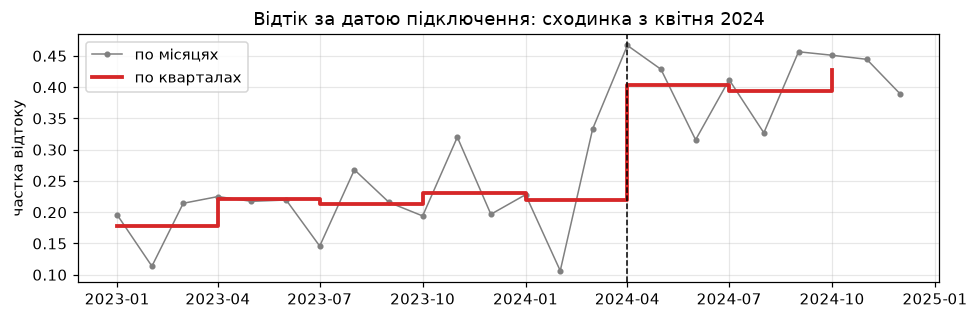

In [19]:
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній)
by_branch = raw.groupby('філія')[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
display(by_branch)

# 2) частка відтоку по кварталах дати підключення
conn = pd.to_datetime(raw['дата_підключення'])
by_q = raw.groupby(conn.dt.to_period('Q'))[TARGET].agg(частка_відтоку='mean', клієнтів='size')
display(by_q.round(3).T)

by_m = raw.groupby(conn.dt.to_period('M'))[TARGET].mean()
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(by_m.index.to_timestamp(), by_m.values, marker='o', ms=3, lw=1, color='grey', label='по місяцях')
ax.step(by_q.index.to_timestamp(), by_q['частка_відтоку'], where='post', lw=2.5, color='C3', label='по кварталах')
ax.axvline(pd.Timestamp('2024-04-01'), ls='--', color='k', lw=1)
ax.set_ylabel('частка відтоку'); ax.set_title('Відтік за датою підключення: сходинка з квітня 2024')
ax.legend(); plt.tight_layout(); plt.show()

Між філіями відтік відрізняється плавно (від 0,26 до 0,33, найвищий у Ф-05 Північ) - це
схоже на звичайну різницю між районами. А за датою підключення видно **сходинку**: усі
квартали до 2024 Q1 тримаються на 0,18-0,23, а з 2024 Q2 різко 0,39-0,43. Плавна сезонність
так не виглядає, це схоже на зміну правила обліку в CRM з квітня 2024. Підозрюю дату підключення.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'        # 'філія' або 'дата_підключення' - що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

BREAK_DATE = pd.Timestamp('2024-04-01')     # дата-злам, видно на графіку вище
source = (pd.to_datetime(raw['дата_підключення']) >= BREAK_DATE).astype(int)
print('клієнтів, підключених після зламу: %d з %d' % (source.sum(), len(source)))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

клієнтів, підключених після зламу: 448 з 1200


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.752
ті самі ознаки передбачають ВІДТІК  : AUC 0.812 ± 0.022


AUC передбачення джерела помітно вища за 0,5 - отже за чесними ознаками видно, з якого
періоду клієнт. Подивимось, через що саме, і чи пояснює це сходинку.

In [21]:
period = source.map({0: 'до квітня 2024', 1: 'після'})
print('частки швидкостей тарифу в кожному періоді:')
display(pd.crosstab(period, raw['швидкість_тарифу_Мбіт'], normalize='index').round(2))
print('частка автоплатежу:', raw.groupby(period)['автоплатіж'].apply(lambda s: (s == 'так').mean()).round(2).to_dict())

# чи пояснюють сходинку ознаки клієнта? порівнюю в межах тієї самої групи швидкості
fast = np.where(raw['швидкість_тарифу_Мбіт'] >= 500, 'швидкий (>=500)', 'повільний (<500)')
step = raw.groupby([fast, period])[TARGET].mean().unstack().round(3)
display(step)

# якість моделі всередині кожного періоду окремо (прогнози з 5-кратної перевірки)
p_oof = cross_val_predict(make_pipe(X4, logreg()), X4, y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                          method='predict_proba')[:, 1]
AUC_IN_PERIOD = {nm: roc_auc_score(y[source == k], p_oof[source == k])
                 for k, nm in [(0, 'до квітня 2024'), (1, 'після')]}
print('AUC усередині періоду:', {k: round(v, 3) for k, v in AUC_IN_PERIOD.items()},
      '| разом: %.3f' % roc_auc_score(y, p_oof))

частки швидкостей тарифу в кожному періоді:


швидкість_тарифу_Мбіт,50,100,200,300,400,500,600,800,1000
дата_підключення,,,,,,,,,
до квітня 2024,0.15,0.27,0.28,0.10,0.05,0.06,0.03,0.00,0.05
після,0.05,0.19,0.28,0.04,0.19,0.03,0.09,0.02,0.12


частка автоплатежу: {'до квітня 2024': 0.42, 'після': 0.61}


дата_підключення,до квітня 2024,після
повільний (<500),0.164,0.364
швидкий (>=500),0.495,0.540


AUC усередині періоду: {'до квітня 2024': 0.806, 'після': 0.823} | разом: 0.810


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [22]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.977
2. мінус цільовий витік,22,0.976
3. мінус оцінки людини,21,0.829
4. мінус артефакт збору,20,0.812


чесне число: 0.812 ± 0.022


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [23]:
SLOW_OLD, SLOW_NEW = step.loc['повільний (<500)', 'до квітня 2024'], step.loc['повільний (<500)', 'після']
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = (
    'сходинка різка (квартали до 2024 Q2 - ~0,2, після - ~0,4) і не пояснюється ознаками клієнта: '
    'навіть серед повільних тарифів відтік після квітня %.2f проти %.2f до, тобто змінилось правило '
    'обліку, а не клієнти; з датою модель вчиться "підключився після квітня = піде", і це не '
    'перенесеться ні на нових клієнтів, ні на іншу CRM. Дату викидаю, а те, що період і далі '
    'вгадується з AUC %.2f через швидкість тарифу й автоплатіж, звітую окремо разом з AUC '
    'усередині кожного періоду (%.2f і %.2f)'
    % (SLOW_NEW, SLOW_OLD, auc_src.mean(), AUC_IN_PERIOD['до квітня 2024'], AUC_IN_PERIOD['після']))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '-', DECISION_WHY)

викинути - сходинка різка (квартали до 2024 Q2 - ~0,2, після - ~0,4) і не пояснюється ознаками клієнта: навіть серед повільних тарифів відтік після квітня 0.36 проти 0.16 до, тобто змінилось правило обліку, а не клієнти; з датою модель вчиться "підключився після квітня = піде", і це не перенесеться ні на нових клієнтів, ні на іншу CRM. Дату викидаю, а те, що період і далі вгадується з AUC 0.75 через швидкість тарифу й автоплатіж, звітую окремо разом з AUC усередині кожного періоду (0.81 і 0.82)


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [24]:
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    # у схемі 5 x 4 = 20 навчань, тому час перераховую на 100 навчань
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) * 100 / len(a), 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.812,0.022,8.9
одне дерево,0.748,0.021,4.7
випадковий ліс,0.826,0.020,101.0
гістограмний бустинг,0.817,0.018,286.5


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [25]:
def paired(a, b):
    '''Повертає (середня різниця, півширина 95% інтервалу).'''
    d = np.asarray(b) - np.asarray(a)          # різниця по кожній згортці (поділи однакові)
    n = len(d)
    h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return float(d.mean()), float(h)


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
PAIRED = {}
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    PAIRED[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0135 ± 0.0062   значуще


гістограмний бустинг   проти логістичної: +0.0051 ± 0.0080   у межах шуму


In [26]:
T = cmp_models['с на 100 навчань']
CHOSEN_MODEL = 'випадковий ліс'     # назва з MODELS
CHOSEN_WHY = (
    'якість: AUC %.3f, найвища, і парне порівняння дає %+.4f ± %.4f проти логістичної - значуще, '
    'а бустинг (%+.4f ± %.4f) не кращий за логістичну; стабільність: розкид %.3f, як у інших; '
    'швидкість: %.0f с на 100 навчань проти %.1f с у логістичної - повільніше, але модель '
    'перенавчають раз на тиждень, тож це прийнятно; інтерпретованість: гірша за логістичну, '
    'тому в частині 2 пояснюю її через перестановочну важливість, PDP і SHAP'
    % (cmp_models.loc['випадковий ліс', 'AUC'], *PAIRED['випадковий ліс'], *PAIRED['гістограмний бустинг'],
       cmp_models.loc['випадковий ліс', '±'], T['випадковий ліс'], T['логістична регресія']))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '-', CHOSEN_WHY)

обрано: випадковий ліс - якість: AUC 0.826, найвища, і парне порівняння дає +0.0135 ± 0.0062 проти логістичної - значуще, а бустинг (+0.0051 ± 0.0080) не кращий за логістичну; стабільність: розкид 0.020, як у інших; швидкість: 101 с на 100 навчань проти 8.9 с у логістичної - повільніше, але модель перенавчають раз на тиждень, тож це прийнятно; інтерпретованість: гірша за логістичну, тому в частині 2 пояснюю її через перестановочну важливість, PDP і SHAP


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [27]:
def add_features(X):
    '''Додає сконструйовані ознаки. Приймає і повертає матрицю ознак.'''
    F = X.copy()
    # 1) гривень за 1 Мбіт/с: хто переплачує за свою швидкість, той охочіше піде до конкурента
    F['грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # 2) звернень на місяць обслуговування: 3 звернення за 2 місяці і за 5 років - різні історії;
    #    часті звернення = клієнт незадоволений
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # 3) аварій на одне звернення: якщо аварії є, а клієнт не скаржиться, він уже "махнув рукою"
    F['аварій_на_звернення'] = F['аварій_на_ділянці_за_квартал'] / (F['кількість_звернень_у_підтримку'] + 1)
    # 4) ГБ на гривню: хто платить багато, а користується мало, той відчуває, що платить даремно
    F['ГБ_на_грн'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [28]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.811 ± 0.021
приріст проти базового набору: -0.0010 ± 0.0031   у межах шуму


In [29]:
# для повноти: чи дають нові ознаки щось лісу (ліс + нові ознаки проти лісу на старих)
t0 = time.time()
rf4 = cross_val_score(make_pipe(X4, MODELS['випадковий ліс']), X4, y, cv=cv, scoring='roc_auc')
rf5 = cross_val_score(make_pipe(X5, MODELS['випадковий ліс']), X5, y, cv=cv, scoring='roc_auc')
T_RF2 = time.time() - t0
GAIN_FEAT_LR = paired(base, auc5)
GAIN_MODEL = PAIRED['випадковий ліс']
GAIN_FEAT_RF = paired(rf4, rf5)
print('ліс на нових ознаках: AUC %.3f; приріст проти лісу на старих: %+0.4f ± %.4f   %s'
      % (rf5.mean(), *GAIN_FEAT_RF, 'значуще' if abs(GAIN_FEAT_RF[0]) > GAIN_FEAT_RF[1] else 'у межах шуму'))

ліс на нових ознаках: AUC 0.826; приріст проти лісу на старих: +0.0000 ± 0.0040   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [30]:
FEATURES_VS_MODEL = (
    'складніша модель дала більше: ліс замість логістичної %+.4f ± %.4f (значуще) ціною %.0f с '
    'на 100 навчань замість %.1f с; мої нові ознаки не дали нічого ні логістичній (%+.4f ± %.4f), '
    'ні лісу (%+.4f ± %.4f) - обидва в межах шуму: відношення платежу, трафіку і звернень несуть '
    'ту саму інформацію, що вже була в моделі, просто в іншій формі. Висновок: ознака допомагає, '
    'лише коли додає форму, якої модель не бачила (див. розділ 10.2б)'
    % (*GAIN_MODEL, T['випадковий ліс'], T['логістична регресія'], *GAIN_FEAT_LR, *GAIN_FEAT_RF))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

складніша модель дала більше: ліс замість логістичної +0.0135 ± 0.0062 (значуще) ціною 101 с на 100 навчань замість 8.9 с; мої нові ознаки не дали нічого ні логістичній (-0.0010 ± 0.0031), ні лісу (+0.0000 ± 0.0040) - обидва в межах шуму: відношення платежу, трафіку і звернень несуть ту саму інформацію, що вже була в моделі, просто в іншій формі. Висновок: ознака допомагає, лише коли додає форму, якої модель не бачила (див. розділ 10.2б)


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [31]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.823
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

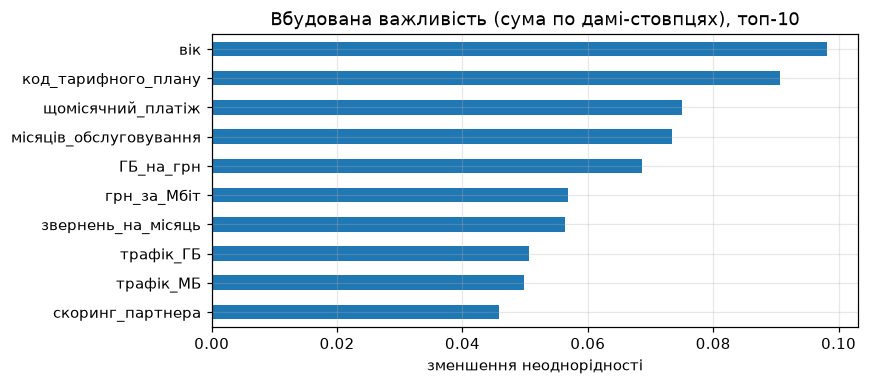

In [32]:
# 1) імена після перетворення
prep_ = model.named_steps['prep']
names_out = prep_.get_feature_names_out()
# 2) кожному стовпцю після перетворення ставлю у відповідність вихідну ознаку і підсумовую
num_cols = list(prep_.transformers_[0][2])
cat_cols = list(prep_.transformers_[1][2])
cats = prep_.named_transformers_['cat'].named_steps['ohe'].categories_
origin = num_cols + [c for c, lv in zip(cat_cols, cats) for _ in lv]
assert len(origin) == len(names_out)
gini_imp = (pd.Series(model.named_steps['clf'].feature_importances_, index=origin)
              .groupby(level=0).sum().sort_values(ascending=False))
# 3) топ-10
fig, ax = plt.subplots(figsize=(8, 3.6))
gini_imp.head(10)[::-1].plot.barh(ax=ax, color='C0')
ax.set_title('Вбудована важливість (сума по дамі-стовпцях), топ-10'); ax.set_xlabel('зменшення неоднорідності')
plt.tight_layout(); plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [33]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.070624
ГБ_на_грн,0.026070
місяців_обслуговування,0.024655
щомісячний_платіж,0.023868
швидкість_тарифу_Мбіт,0.009033
звернень_на_місяць,0.006724
грн_за_Мбіт,0.006109
тип_підключення,0.002697
знижка_відсоток,0.002397
кількість_звернень_у_підтримку,0.002329


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [34]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
both_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
both_imp['ранг вбудованої'] = both_imp['вбудована'].rank(ascending=False).astype(int)
both_imp['ранг перестановочної'] = both_imp['перестановочна'].rank(ascending=False).astype(int)
both_imp = both_imp.sort_values('вбудована', ascending=False)
display(both_imp.round(4))
print('рівнів у код_тарифного_плану: %d, унікальних у скоринг_партнера: %d'
      % (X5['код_тарифного_плану'].nunique(), X5['скоринг_партнера'].nunique()))

,вбудована,перестановочна,ранг вбудованої,ранг перестановочної
вік,0.0982,0.0706,1,1
код_тарифного_плану,0.0906,-0.0030,2,23
щомісячний_платіж,0.0751,0.0239,3,4
місяців_обслуговування,0.0734,0.0247,4,3
ГБ_на_грн,0.0687,0.0261,5,2
грн_за_Мбіт,0.0568,0.0061,6,7
звернень_на_місяць,0.0564,0.0067,7,6
трафік_ГБ,0.0505,0.0014,8,12
трафік_МБ,0.0498,0.0007,9,15
скоринг_партнера,0.0458,0.0012,10,13


рівнів у код_тарифного_плану: 40, унікальних у скоринг_партнера: 1200


In [35]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = (
    'за вбудованою вона на %d-му місці (%.3f), а перестановочна %+.4f - перемішування нічого не '
    'ламає; після одиничного кодування це 40 дамі-стовпців, і кожен дає дереву ще один можливий '
    'поділ, тож на навчальних даних ліс завжди знаходить серед них поділи, які трохи зменшують '
    'неоднорідність випадково, а сума цих дрібних "випадкових" виграшів по 40 стовпцях і 300 деревах '
    'стає великою; вбудована важливість рахується на навчальних даних і цього не помічає. Те саме, '
    'слабше, видно на скоринг_партнера (1200 різних значень, %d-е місце за вбудованою, '
    'перестановочна %+.4f)'
    % (both_imp.loc['код_тарифного_плану', 'ранг вбудованої'], both_imp.loc['код_тарифного_плану', 'вбудована'],
       both_imp.loc['код_тарифного_плану', 'перестановочна'],
       both_imp.loc['скоринг_партнера', 'ранг вбудованої'], both_imp.loc['скоринг_партнера', 'перестановочна']))
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)
print(FAKE_IMPORTANT_WHY)

хибно важлива ознака: код_тарифного_плану
за вбудованою вона на 2-му місці (0.091), а перестановочна -0.0030 - перемішування нічого не ламає; після одиничного кодування це 40 дамі-стовпців, і кожен дає дереву ще один можливий поділ, тож на навчальних даних ліс завжди знаходить серед них поділи, які трохи зменшують неоднорідність випадково, а сума цих дрібних "випадкових" виграшів по 40 стовпцях і 300 деревах стає великою; вбудована важливість рахується на навчальних даних і цього не помічає. Те саме, слабше, видно на скоринг_партнера (1200 різних значень, 10-е місце за вбудованою, перестановочна +0.0012)


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [36]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
corr = FINAL_X.select_dtypes('number').corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename('r').reset_index().rename(columns={'level_0': 'ознака 1', 'level_1': 'ознака 2'}))
pairs = pairs.reindex(pairs['r'].abs().sort_values(ascending=False).index)
display(pairs.head(5).round(4))
ratio = (FINAL_X['трафік_МБ'] / FINAL_X['трафік_ГБ']).median()
print('медіана трафік_МБ / трафік_ГБ = %.0f (≈1024 МБ в 1 ГБ)' % ratio)

,ознака 1,ознака 2,r
106,трафік_ГБ,трафік_МБ,0.9997
175,трафік_МБ,ГБ_на_грн,0.8896
111,трафік_ГБ,ГБ_на_грн,0.8894
142,аварій_на_ділянці_за_квартал,аварій_на_звернення,0.8318
52,швидкість_тарифу_Мбіт,щомісячний_платіж,0.7379


медіана трафік_МБ / трафік_ГБ = 1023 (≈1024 МБ в 1 ГБ)


In [37]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

def refit_perm(F):
    # той самий поділ і та сама модель, що й FINAL, лише без деяких стовпців
    a, b, c, d = train_test_split(F, y, test_size=0.3, stratify=y, random_state=SEED)
    m = make_pipe(F, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(a, c)
    p = permutation_importance(m, b, d, n_repeats=10, random_state=SEED, scoring='roc_auc')
    return pd.Series(p.importances_mean, index=F.columns), roc_auc_score(d, m.predict_proba(b)[:, 1])

pi_noMB, auc_noMB = refit_perm(FINAL_X.drop(columns=[DUP_PAIR[1]]))
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f   (AUC моделі %.3f)' % (DUP_PAIR[0], pi_noMB[DUP_PAIR[0]], auc_noMB))
# трафік є ще й у моїй ознаці ГБ_на_грн - це третій носій тієї самої інформації
print('   %-28s %+.4f   <- теж несе трафік' % ('ГБ_на_грн', pi_noMB['ГБ_на_грн']))
pi_one, auc_one = refit_perm(FINAL_X.drop(columns=[DUP_PAIR[1], 'ГБ_на_грн']))
print('без %s і без ГБ_на_грн:' % DUP_PAIR[1])
print('   %-28s %+.4f   (AUC моделі %.3f)' % (DUP_PAIR[0], pi_one[DUP_PAIR[0]], auc_one))
_, auc_none = refit_perm(FINAL_X.drop(columns=DUP_PAIR + ['ГБ_на_грн']))
print('без жодної ознаки трафіку: AUC моделі %.3f (з ними %.3f)' % (auc_none, auc_hold))

у повній моделі:
   трафік_ГБ                    +0.0014
   трафік_МБ                    +0.0007


без трафік_МБ:
   трафік_ГБ                    +0.0039   (AUC моделі 0.822)
   ГБ_на_грн                    +0.0297   <- теж несе трафік


без трафік_МБ і без ГБ_на_грн:
   трафік_ГБ                    +0.0246   (AUC моделі 0.817)


без жодної ознаки трафіку: AUC моделі 0.796 (з ними 0.823)


In [38]:
DUP_EXPLANATION = (
    'у повній моделі обидві ознаки виглядають непотрібними (%+.4f і %+.4f), бо трафік_МБ = '
    'трафік_ГБ * 1024 (r = %.4f): коли перемішую одну, ліс бере ту саму інформацію з другої. Без '
    'трафік_МБ важливість трафік_ГБ зросла до %+.4f, а коли прибрала ще й ГБ_на_грн (третій носій '
    'трафіку) - до %+.4f, тобто в %.0f разів. Якщо ж викинути весь трафік, AUC падає з %.3f до %.3f. '
    'Отже "важливість нуль" означала "є дублікат", а не "ознака не потрібна"'
    % (perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], corr.loc[DUP_PAIR[0], DUP_PAIR[1]],
       pi_noMB[DUP_PAIR[0]], pi_one[DUP_PAIR[0]], pi_one[DUP_PAIR[0]] / max(perm_imp[DUP_PAIR[0]], 1e-4),
       auc_hold, auc_none))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

у повній моделі обидві ознаки виглядають непотрібними (+0.0014 і +0.0007), бо трафік_МБ = трафік_ГБ * 1024 (r = 0.9997): коли перемішую одну, ліс бере ту саму інформацію з другої. Без трафік_МБ важливість трафік_ГБ зросла до +0.0039, а коли прибрала ще й ГБ_на_грн (третій носій трафіку) - до +0.0246, тобто в 18 разів. Якщо ж викинути весь трафік, AUC падає з 0.823 до 0.796. Отже "важливість нуль" означала "є дублікат", а не "ознака не потрібна"


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки: ['вік', 'ГБ_на_грн', 'місяців_обслуговування']


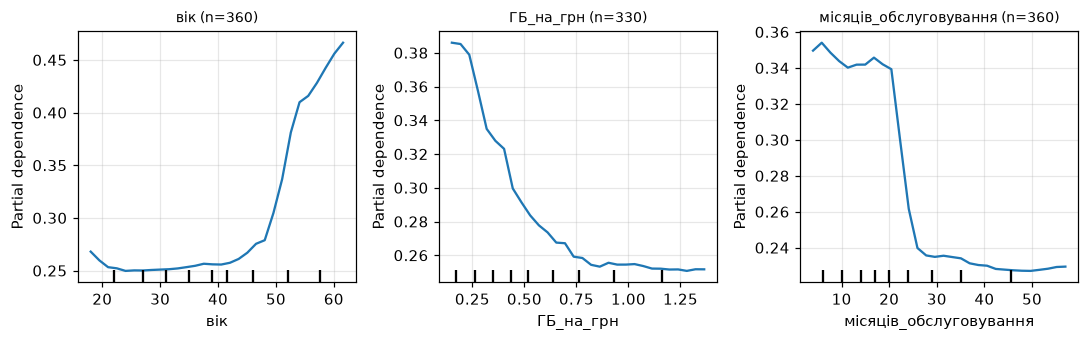

вік                  прогноз від 0.250 до 0.466, мінімум при 24.0
ГБ_на_грн            прогноз від 0.251 до 0.386, мінімум при 1.3
місяців_обслуговування прогноз від 0.227 до 0.354, мінімум при 49.7


In [39]:
from sklearn.inspection import PartialDependenceDisplay

num_feats = [c for c in perm_imp.index if str(FINAL_X[c].dtype) != 'category']
TOP3 = num_feats[:3]
print('три найважливіші числові ознаки:', TOP3)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
PDP = {}
for ax, f in zip(axes, TOP3):
    sub = Xte.dropna(subset=[f])          # PDP будую на рядках, де ця ознака заповнена
    PartialDependenceDisplay.from_estimator(model, sub, [f], kind='average', ax=ax,
                                            grid_resolution=30)
    r = partial_dependence(model, sub, [f], kind='average', grid_resolution=30)
    PDP[f] = (r['grid_values'][0], r['average'][0])
    ax.set_title('%s (n=%d)' % (f, len(sub)), fontsize=9)
plt.tight_layout(); plt.show()
for f, (g, av) in PDP.items():
    print('%-20s прогноз від %.3f до %.3f, мінімум при %.1f' % (f, av.min(), av.max(), g[np.argmin(av)]))

Як читаю криві (вертикаль - середня ймовірність відходу):

* **вік** - від 18 до ~25 років ризик трохи спадає, до ~45 тримається рівно (~0,25), а після
  50 різко росте до ~0,47: старші клієнти йдуть значно частіше. Форма немонотонна (див. 10.2).
* **ГБ_на_грн** - монотонно спадає від ~0,39 до ~0,25 і після ~0,8 ГБ/грн виходить на плато:
  хто мало користується інтернетом за свої гроші, той частіше йде; хто "відбиває" платіж
  трафіком - лишається.
* **місяців_обслуговування** - не плавна крива, а **сходинка**: до ~20 місяців ризик ~0,35, між
  20 і 27 місяцями падає до ~0,23 і далі майже не змінюється. Схоже на типовий дворічний договір:
  хто пережив перші два роки, той уже "свій" клієнт.

`ГБ_на_грн` має пропуски (бо їх має `трафік_ГБ`), тому для неї PDP побудовано лише на рядках, де
вона заповнена (n на заголовку); вік і стаж заповнені повністю.

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

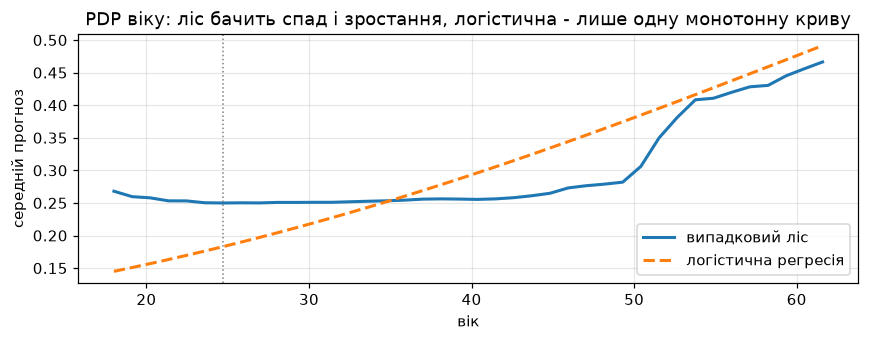

вік,"(17, 25]","(25, 30]","(30, 35]","(35, 40]","(40, 45]","(45, 50]","(50, 55]","(55, 60]","(60, 90]"
частка_відтоку,0.221,0.203,0.19,0.234,0.188,0.28,0.458,0.515,0.663
клієнтів,217.000,123.000,153.00,192.000,138.000,132.00,96.000,66.000,83.000


мінімум ризику за лісом при віці 25


In [40]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
r_rf = partial_dependence(model, Xte, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
r_lr = partial_dependence(lr_model, Xte, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
AGE_GRID, AGE_RF = r_rf['grid_values'][0], r_rf['average'][0]
AGE_MIN = float(AGE_GRID[np.argmin(AGE_RF)])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(AGE_GRID, AGE_RF, lw=2, label='випадковий ліс')
ax.plot(r_lr['grid_values'][0], r_lr['average'][0], lw=2, ls='--', label='логістична регресія')
ax.axvline(AGE_MIN, color='grey', lw=1, ls=':')
ax.set_xlabel('вік'); ax.set_ylabel('середній прогноз'); ax.legend()
ax.set_title('PDP віку: ліс бачить спад і зростання, логістична - лише одну монотонну криву')
plt.tight_layout(); plt.show()

# звірка з сирими даними
age_bins = pd.cut(raw['вік'], [17, 25, 30, 35, 40, 45, 50, 55, 60, 90])
display(raw.groupby(age_bins, observed=True)[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3).T)
print('мінімум ризику за лісом при віці %.0f' % AGE_MIN)

In [41]:
NONLINEAR_MEANING = ('найменше йдуть клієнти від ~%.0f до ~45 років; наймолодші йдуть трохи частіше '
                     '(частіше переїжджають і шукають дешевше), а після 50 ризик різко росте і серед 60+ '
                     'іде %.0f %% - у сирих даних та сама несиметрична U-подібна форма'
                     % (AGE_MIN, 100 * raw.loc[raw['вік'] > 60, TARGET].mean()))
NONLINEAR_FIX = ('додати ознаку "квадрат відхилення віку від %.0f": (вік - %.0f)^2 - тоді лінійна модель '
                 'зможе мати мінімум посередині і прискорене зростання для старших' % (AGE_MIN, AGE_MIN))
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

найменше йдуть клієнти від ~25 до ~45 років; наймолодші йдуть трохи частіше (частіше переїжджають і шукають дешевше), а після 50 ризик різко росте і серед 60+ іде 66 % - у сирих даних та сама несиметрична U-подібна форма
додати ознаку "квадрат відхилення віку від 25": (вік - 25)^2 - тоді лінійна модель зможе мати мінімум посередині і прискорене зростання для старших


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [42]:
# 1) значення, при якому ризик мінімальний, зчитане з PDP лісу вище
print('мінімум ризику: вік %.1f' % AGE_MIN)

# 2) ознака «квадрат відхилення від цього значення»
def add_age_sq(X):
    F = X.copy()
    F['вік_відхилення_кв'] = (F['вік'] - AGE_MIN) ** 2
    return F
X6 = add_age_sq(FINAL_X)

# 3) парне порівняння логістичної регресії з нею і без неї (ті самі 20 поділів)
auc6 = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc5, auc6)
print('логістична без ознаки: %.3f, з ознакою: %.3f' % (auc5.mean(), auc6.mean()))
print('приріст: %+0.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))
# перевірка тези "лісу це нічого не дасть"
rf6 = cross_val_score(make_pipe(X6, MODELS['випадковий ліс']), X6, y, cv=cv, scoring='roc_auc')
m_qrf, h_qrf = paired(rf5, rf6)
print('ліс з ознакою проти лісу без: %+0.4f ± %.4f   %s'
      % (m_qrf, h_qrf, 'значуще' if abs(m_qrf) > h_qrf else 'у межах шуму'))
print('логістична з ознакою (%.3f) проти лісу (%.3f)' % (auc6.mean(), rf5.mean()))

мінімум ризику: вік 24.7


логістична без ознаки: 0.811, з ознакою: 0.830
приріст: +0.0186 ± 0.0053   значуще


ліс з ознакою проти лісу без: +0.0042 ± 0.0035   значуще
логістична з ознакою (0.830) проти лісу (0.826)


In [43]:
QUAD_GAIN = m_q     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0186


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

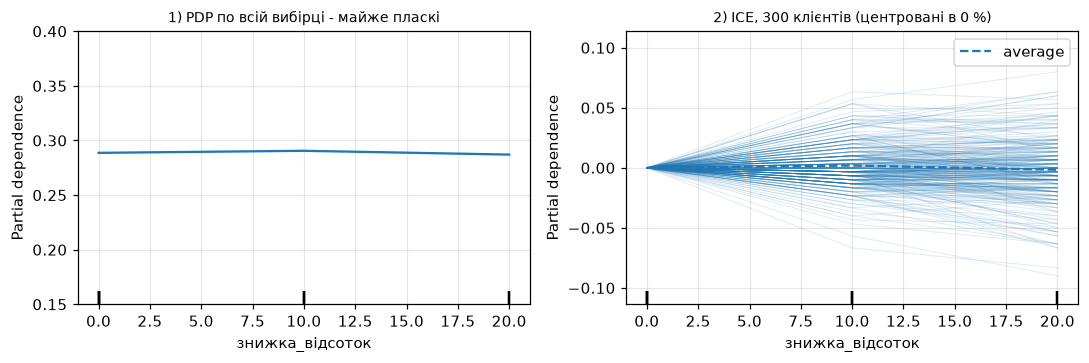

PDP: [0.289 0.291 0.287]
ICE: у 28 % клієнтів ризик від знижки росте, у 33 % спадає


In [44]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
d1 = PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=axes[0])
d1.axes_[0][0].set_ylim(0.15, 0.40)    # без цього matplotlib розтягує різницю в 0,003 на весь рисунок
axes[0].set_title('1) PDP по всій вибірці - майже пласкі', fontsize=9)
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='both', ax=axes[1],
                                        subsample=300, random_state=SEED, centered=True,
                                        ice_lines_kw={'alpha': 0.15, 'lw': 0.6})
axes[1].set_title('2) ICE, 300 клієнтів (центровані в 0 %)', fontsize=9)
plt.tight_layout(); plt.show()

ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
ice_delta = ice[:, -1] - ice[:, 0]          # зміна прогнозу клієнта при знижці 20 % замість 0 %
print('PDP: %s' % np.round(partial_dependence(model, FINAL_X, ['знижка_відсоток'])['average'][0], 3))
print('ICE: у %.0f %% клієнтів ризик від знижки росте, у %.0f %% спадає'
      % (100 * (ice_delta > 0.01).mean(), 100 * (ice_delta < -0.01).mean()))

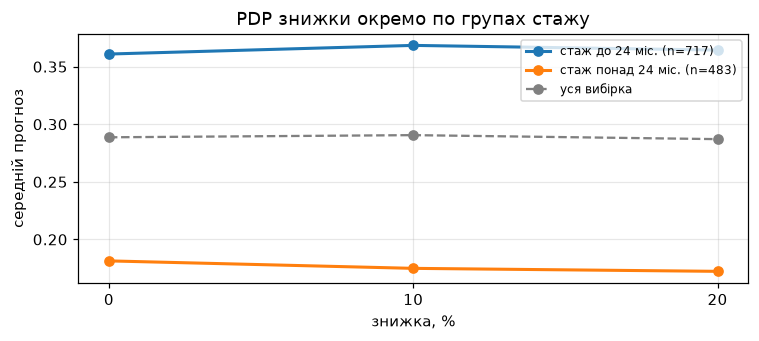

стаж до 24 міс.      0% -> 20%: 0.361 -> 0.364
стаж понад 24 міс.   0% -> 20%: 0.181 -> 0.172


In [45]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
SHORT = FINAL_X['місяців_обслуговування'] <= 24
groups = {'стаж до 24 міс.': SHORT, 'стаж понад 24 міс.': ~SHORT}
PDP_GR = {}
fig, ax = plt.subplots(figsize=(7, 3.2))
for nm, mask in groups.items():
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    PDP_GR[nm] = r['average'][0]
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', lw=2, label='%s (n=%d)' % (nm, mask.sum()))
r_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
ax.plot(r_all['grid_values'][0], r_all['average'][0], marker='o', ls='--', color='grey', label='уся вибірка')
ax.set_xticks([0, 10, 20]); ax.set_xlabel('знижка, %'); ax.set_ylabel('середній прогноз')
ax.set_title('PDP знижки окремо по групах стажу'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for nm, v in PDP_GR.items():
    print('%-20s 0%% -> 20%%: %.3f -> %.3f' % (nm, v[0], v[-1]))

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [46]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
tenure_grp = np.where(raw['місяців_обслуговування'] <= 24, 'стаж до 24', 'стаж понад 24')
emp = (raw.assign(група=tenure_grp)
          .pivot_table(index='знижка_відсоток', columns='група', values=TARGET,
                       aggfunc=['mean', 'size']))
emp.columns = ['відтік: ' + g if a == 'mean' else 'клієнтів: ' + g for a, g in emp.columns]
display(emp.round(3))
EMP = raw.assign(група=tenure_grp).groupby(['група', 'знижка_відсоток'])[TARGET].mean()

,відтік: стаж до 24,відтік: стаж понад 24,клієнтів: стаж до 24,клієнтів: стаж понад 24
знижка_відсоток,,,,
0,0.296,0.212,307,189
10,0.423,0.138,220,167
20,0.458,0.071,190,127


In [47]:
INTERACTION_FOUND = (
    'у сирих даних у новачків (стаж до 24 міс.) зі знижкою відтік ВИЩИЙ (%.2f без знижки -> %.2f при 20 %%), '
    'а в давніх клієнтів навпаки НИЖЧИЙ (%.2f -> %.2f); по всій вибірці ці ефекти гасять один одного '
    'і PDP пласкі (%.3f -> %.3f). Модель відтворює напрям, але дуже слабко (новачки %.3f -> %.3f, давні '
    '%.3f -> %.3f): знижка має лише 3 значення і слабку загальну важливість, тож дерева рідко по ній '
    'ріжуть, - це вже питання до моделі, а не до PDP (див. 10.3в)'
    % (EMP['стаж до 24', 0], EMP['стаж до 24', 20], EMP['стаж понад 24', 0], EMP['стаж понад 24', 20],
       r_all['average'][0][0], r_all['average'][0][-1], PDP_GR['стаж до 24 міс.'][0], PDP_GR['стаж до 24 міс.'][-1],
       PDP_GR['стаж понад 24 міс.'][0], PDP_GR['стаж понад 24 міс.'][-1]))
BUSINESS_ACTION = (
    'знижку як інструмент утримання пропонувати давнім клієнтам, де вона пов\'язана з меншим відтоком; '
    'новачкам знижка не допомагає (можливо, її дають тим, хто вже прийшов "на акцію" і так само піде '
    'після неї) - їм краще пропонувати інше (якість, підтримка); а щоб знати, чи знижка ПРИЧИНА, '
    'потрібен A/B-тест: частині ризикових клієнтів дати знижку, частині ні, і порівняти')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

у сирих даних у новачків (стаж до 24 міс.) зі знижкою відтік ВИЩИЙ (0.30 без знижки -> 0.46 при 20 %), а в давніх клієнтів навпаки НИЖЧИЙ (0.21 -> 0.07); по всій вибірці ці ефекти гасять один одного і PDP пласкі (0.289 -> 0.287). Модель відтворює напрям, але дуже слабко (новачки 0.361 -> 0.364, давні 0.181 -> 0.172): знижка має лише 3 значення і слабку загальну важливість, тож дерева рідко по ній ріжуть, - це вже питання до моделі, а не до PDP (див. 10.3в)
знижку як інструмент утримання пропонувати давнім клієнтам, де вона пов'язана з меншим відтоком; новачкам знижка не допомагає (можливо, її дають тим, хто вже прийшов "на акцію" і так само піде після неї) - їм краще пропонувати інше (якість, підтримка); а щоб знати, чи знижка ПРИЧИНА, потрібен A/B-тест: частині ризикових клієнтів дати знижку, частині ні, і порівняти


### 10.3в - замикаю цикл ще раз (моє доповнення)

Якщо модель сама взаємодію "знижка x стаж" майже не вивчила, її можна дати явно - так само,
як квадрат віку в 10.2б: знижка окремо для новачків і окремо для давніх клієнтів. Порівнюю парно
на тих самих 20 поділах.

In [48]:
def add_discount_split(X):
    F = X.copy()
    short = (F['місяців_обслуговування'] <= 24).astype(float)
    F['знижка_новачку'] = F['знижка_відсоток'] * short          # гіпотеза: новачкам знижка не допомагає
    F['знижка_давньому'] = F['знижка_відсоток'] * (1 - short)   # гіпотеза: давнім - допомагає
    return F

X7i = add_discount_split(FINAL_X)
a_lr_i = cross_val_score(make_pipe(X7i, logreg()), X7i, y, cv=cv, scoring='roc_auc')
a_rf_i = cross_val_score(make_pipe(X7i, MODELS['випадковий ліс']), X7i, y, cv=cv, scoring='roc_auc')
INT_GAIN_LR, INT_GAIN_RF = paired(auc5, a_lr_i), paired(rf5, a_rf_i)
for nm, (m, h) in [('логістична', INT_GAIN_LR), ('ліс', INT_GAIN_RF)]:
    print('%-11s з розділеною знижкою: %+0.4f ± %.4f   %s' % (nm, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

# логістична з обома ознаками, підказаними поясненнями (вік^2 і розділена знижка)
X7 = add_discount_split(X6)
auc7 = cross_val_score(make_pipe(X7, logreg()), X7, y, cv=cv, scoring='roc_auc')
print('логістична + вік^2 + розділена знижка: AUC %.3f ± %.3f (ліс на X5: %.3f)' % (auc7.mean(), auc7.std(), rf5.mean()))
print('проти логістичної на X5: %+0.4f ± %.4f;  проти лісу: %+0.4f ± %.4f' % (*paired(auc5, auc7), *paired(rf5, auc7)))
lr7 = make_pipe(X7, logreg()).fit(X7, y)
coef = pd.Series(lr7.named_steps['clf'].coef_[0], index=lr7.named_steps['prep'].get_feature_names_out())
print('коефіцієнти логістичної (стандартизовані):',
      {k.split('__')[1]: round(v, 3) for k, v in coef.items() if 'знижка' in k})

логістична  з розділеною знижкою: +0.0228 ± 0.0058   значуще
ліс         з розділеною знижкою: +0.0105 ± 0.0049   значуще


логістична + вік^2 + розділена знижка: AUC 0.851 ± 0.019 (ліс на X5: 0.826)
проти логістичної на X5: +0.0403 ± 0.0087;  проти лісу: +0.0258 ± 0.0099
коефіцієнти логістичної (стандартизовані): {'знижка_відсоток': -0.094, 'знижка_новачку': 0.485, 'знижка_давньому': -0.666}


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [49]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()
feat_names = np.array([n.split('__', 1)[1] for n in feat_names])   # без префіксів num__ / cat__

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

# перевірка властивості: базовий рівень + сума внесків = прогноз
base_val = expl.expected_value[1] if np.ndim(expl.expected_value) else expl.expected_value
recon = base_val + sv1.sum(axis=1)
print('макс. розбіжність з predict_proba: %.2e' % np.abs(recon - clf.predict_proba(Xte_t[:SAMPLE])[:, 1]).max())

матриця значень Шеплі: (300, 82)
макс. розбіжність з predict_proba: 7.61e-15


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

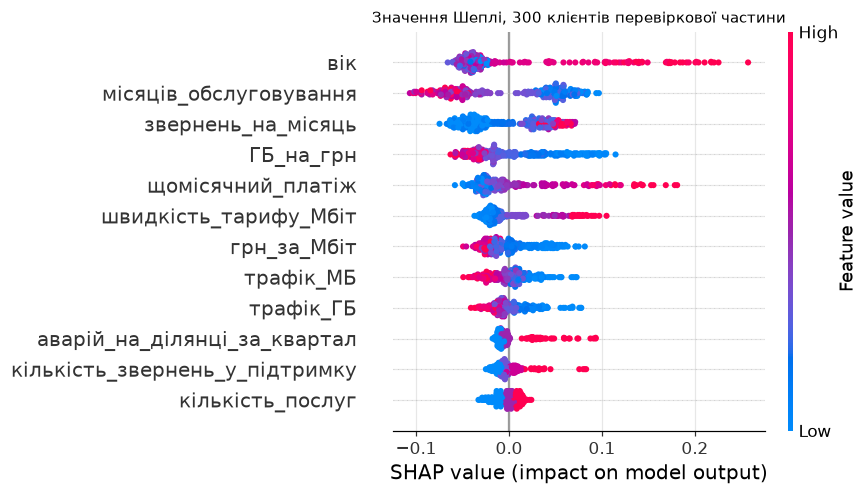

In [50]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=12,
                  plot_size=(8, 4.6), show=False)
plt.title('Значення Шеплі, 300 клієнтів перевіркової частини', fontsize=10)
plt.tight_layout(); plt.show()

Що бачу на beeswarm (колір - значення ознаки, червоне = велике; праворуч = тягне ризик угору):

* **вік**, **щомісячний_платіж**, **звернень_на_місяць**, **швидкість_тарифу** - червоні точки
  праворуч: більші значення підвищують ризик.
* **місяців_обслуговування**, **ГБ_на_грн**, **трафік** - навпаки, червоні ліворуч: давні клієнти
  і ті, хто багато користується, ризикують менше.
* Напрям **не однаковий** для всіх: у віку більшість точок біля нуля або трохи ліворуч, а великий
  внесок угору мають лише старші клієнти - довгий червоний хвіст праворуч. Стовпчикова діаграма
  важливості цього не показує, вона дає одне число на ознаку.

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [51]:
proba_s = model.predict_proba(Xte)[:SAMPLE, 1]
idx = int(np.argmax(proba_s))
print('ризик клієнта: %.3f' % proba_s[idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
display(top3.round(3).to_frame('внесок у ризик'))
print('базовий рівень %.3f + сума всіх внесків %.3f = %.3f' % (base_val, contrib.sum(), base_val + contrib.sum()))
client = Xte.iloc[idx]
display(client[['вік', 'місяців_обслуговування', 'щомісячний_платіж', 'ГБ_на_грн', 'трафік_ГБ',
                'кількість_звернень_у_підтримку', 'знижка_відсоток', 'тариф']].to_frame('цей клієнт'))
PAY_MED = FINAL_X['щомісячний_платіж'].median()
GBG_MED = FINAL_X['ГБ_на_грн'].median()
OLD_SHARE = raw.loc[raw['вік'] > 50, TARGET].mean()
RANK_PAY = int(list(contrib.abs().sort_values(ascending=False).index).index('щомісячний_платіж')) + 1

ризик клієнта: 0.863


,внесок у ризик
вік,0.115
щомісячний_платіж,0.114
ГБ_на_грн,0.105


базовий рівень 0.285 + сума всіх внесків 0.578 = 0.863


,цей клієнт
вік,60.0
місяців_обслуговування,13.0
щомісячний_платіж,649.42
ГБ_на_грн,0.098857
трафік_ГБ,64.2
кількість_звернень_у_підтримку,1.0
знижка_відсоток,10.0
тариф,максимальний


In [52]:
EXPLANATION_FOR_MANAGER = (
    'Клієнт (%.0f років, з нами %.0f міс., тариф "%s", %s) - у групі найвищого ризику, '
    'бо: 1) платить %.0f грн на місяць, у %.1f раза більше за типового абонента (%.0f грн); '
    '2) йому %.0f - серед клієнтів понад 50 років розривають договір %.0f %% проти 29 %% загалом; '
    '3) при цьому користується інтернетом мало - %.2f ГБ на кожну гривню платежу проти звичних %.2f, '
    'тобто фактично платить за те, чим не користується. Варто запитати, чи потрібна йому така '
    'швидкість, і запропонувати тариф, що відповідає його реальному користуванню.'
    % (client['вік'], client['місяців_обслуговування'], client['тариф'],
       'вже має знижку %.0f %%' % client['знижка_відсоток'] if client['знижка_відсоток'] else 'без знижки',
       client['щомісячний_платіж'], client['щомісячний_платіж'] / PAY_MED, PAY_MED,
       client['вік'], 100 * OLD_SHARE, client['ГБ_на_грн'], GBG_MED))
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнт (60 років, з нами 13 міс., тариф "максимальний", вже має знижку 10 %) - у групі найвищого ризику, бо: 1) платить 649 грн на місяць, у 2.1 раза більше за типового абонента (302 грн); 2) йому 60 - серед клієнтів понад 50 років розривають договір 54 % проти 29 % загалом; 3) при цьому користується інтернетом мало - 0.10 ГБ на кожну гривню платежу проти звичних 0.54, тобто фактично платить за те, чим не користується. Варто запитати, чи потрібна йому така швидкість, і запропонувати тариф, що відповідає його реальному користуванню.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [53]:
SHAP_NOT_CAUSAL_FEATURE = 'щомісячний_платіж'
SHAP_NOT_CAUSAL_WHY = (
    'у найризикованішого клієнта це %d-й за величиною внесок (%+.3f), і менеджер скаже "знизимо платіж '
    'знижкою - і він лишиться"; але модель лише помітила, що серед тих, хто йде, частіше трапляються '
    'дорогі платежі, а не що ціна є причиною; мої дані проти такої дії: у клієнта вже є знижка %.0f %%, '
    'а ризик однаково найвищий; йому %.0f міс., а серед новачків до 24 міс. відтік зі знижкою 20 %% '
    '%.2f проти %.2f без знижки. Вік (ще один великий внесок) - ознака, на яку вплинути взагалі не можна'
    % (RANK_PAY, contrib['щомісячний_платіж'], client['знижка_відсоток'], client['місяців_обслуговування'],
       EMP['стаж до 24', 20], EMP['стаж до 24', 0]))
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '-', SHAP_NOT_CAUSAL_WHY)

щомісячний_платіж - у найризикованішого клієнта це 2-й за величиною внесок (+0.114), і менеджер скаже "знизимо платіж знижкою - і він лишиться"; але модель лише помітила, що серед тих, хто йде, частіше трапляються дорогі платежі, а не що ціна є причиною; мої дані проти такої дії: у клієнта вже є знижка 10 %, а ризик однаково найвищий; йому 13 міс., а серед новачків до 24 міс. відтік зі знижкою 20 % 0.46 проти 0.30 без знижки. Вік (ще один великий внесок) - ознака, на яку вплинути взагалі не можна


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [54]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",щомісячний_платіж,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [55]:
# перевіряю, що модель "думає" про час відповіді в тих, хто ніколи не дзвонив (MNAR з розділу 2)
wait_j = list(feat_names).index('середній_час_відповіді_хв')
never = Xte['середній_час_відповіді_хв'].isna().values[:SAMPLE]
print('клієнтів без жодного звернення у вибірці SHAP: %d' % never.sum())
print('їм підставлено медіану: %.1f хв' % prep.named_transformers_['num'].named_steps['imp']
      .statistics_[list(prep.transformers_[0][2]).index('середній_час_відповіді_хв')])
print('середній |внесок| часу відповіді: не дзвонили %.4f, дзвонили %.4f'
      % (np.abs(sv1[never, wait_j]).mean(), np.abs(sv1[~never, wait_j]).mean()))

клієнтів без жодного звернення у вибірці SHAP: 99
їм підставлено медіану: 9.4 хв
середній |внесок| часу відповіді: не дзвонили 0.0080, дзвонили 0.0078


In [56]:
WAIT_MED = prep.named_transformers_['num'].named_steps['imp'].statistics_[
    list(prep.transformers_[0][2]).index('середній_час_відповіді_хв')]
FIFTH_MISTAKE = (
    'середній_час_відповіді_хв: для %d %% клієнтів, які жодного разу не дзвонили в підтримку (MNAR), '
    'конвеєр підставив медіану %.1f хв, і SHAP показує їм внесок "часу відповіді" (у середньому %.4f за '
    'модулем). Менеджер прочитає "цьому клієнту довго відповідали", хоча йому не відповідали жодного '
    'разу, бо він не дзвонив. Внесок насправді означає "не звертався", і правильно це виправити '
    'прапорцем "не звертався" або не показувати цю ознаку в поясненні для таких клієнтів'
    % (100 * raw['середній_час_відповіді_хв'].isna().mean(), WAIT_MED, np.abs(sv1[never, wait_j]).mean()))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

середній_час_відповіді_хв: для 33 % клієнтів, які жодного разу не дзвонили в підтримку (MNAR), конвеєр підставив медіану 9.4 хв, і SHAP показує їм внесок "часу відповіді" (у середньому 0.0080 за модулем). Менеджер прочитає "цьому клієнту довго відповідали", хоча йому не відповідали жодного разу, бо він не дзвонив. Внесок насправді означає "не звертався", і правильно це виправити прапорцем "не звертався" або не показувати цю ознаку в поясненні для таких клієнтів


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

у перевірковій частині 360 клієнтів, пішли 103 (частка 0.286)


з топ-100 за ризиком справді пішли: 64
навмання з 100 знайшли б у середньому: 28.6
lift = 2.24


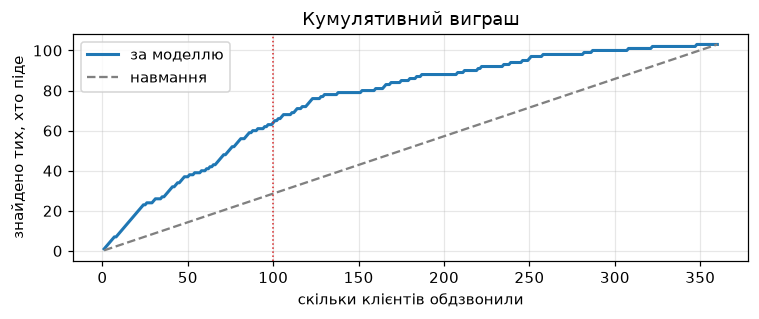

In [57]:
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
p_te = model.predict_proba(Xte)[:, 1]
order = np.argsort(-p_te)
hits = int(yte.values[order[:TOP_N]].sum())
rate_all = yte.mean()
lift = (hits / TOP_N) / rate_all
print('у перевірковій частині %d клієнтів, пішли %d (частка %.3f)' % (len(yte), yte.sum(), rate_all))
print('з топ-%d за ризиком справді пішли: %d' % (TOP_N, hits))
print('навмання з %d знайшли б у середньому: %.1f' % (TOP_N, TOP_N * rate_all))
print('lift = %.2f' % lift)

# крива: скільки тих, хто піде, знайдемо, обдзвонивши перших k клієнтів
k = np.arange(1, len(yte) + 1)
found = np.cumsum(yte.values[order])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(k, found, lw=2, label='за моделлю')
ax.plot(k, k * rate_all, ls='--', color='grey', label='навмання')
ax.axvline(TOP_N, color='C3', lw=1, ls=':'); ax.set_xlabel('скільки клієнтів обдзвонили')
ax.set_ylabel('знайдено тих, хто піде'); ax.legend(); ax.set_title('Кумулятивний виграш')
plt.tight_layout(); plt.show()

In [58]:
LIFT_MEANING = ('обдзвонюючи 100 клієнтів зі списку моделі, відділ утримання потрапить на %d, хто справді '
                'збирається піти, замість ~%.0f при виборі навмання - у %.1f раза більше корисних дзвінків '
                'за той самий тиждень роботи' % (hits, TOP_N * rate_all, lift))
assert LIFT_MEANING
print(LIFT_MEANING)

обдзвонюючи 100 клієнтів зі списку моделі, відділ утримання потрапить на 64, хто справді збирається піти, замість ~29 при виборі навмання - у 2.2 раза більше корисних дзвінків за той самий тиждень роботи


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [59]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_06.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [60]:
# числа для звіту беру прямо зі змінних, щоб вони збігались з виводами вище
dropped = DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT]
REPORT = f"""
Варіант {VARIANT}, файл {DATA} (за номером у списку, викладач іншого не призначав).

1. Метрика - AUC. Відтоку {raw[TARGET].mean():.3f}, тож модель "ніхто не піде" має точність
   {BASELINE_ACC:.3f} і не знаходить жодного клієнта, що піде. AUC не залежить від порога і показує
   те, що потрібно відділу утримання: чи стоїть той, хто піде, у списку вище за того, хто лишиться.
   Метрику і схему (стратифікована 5-кратна, 4 повтори = 20 навчань) обрала до роботи з даними.

2. Викинуті стовпці і момент їх появи:
   - id_клієнта - технічний номер, ознакою не є (модель могла б лише запам'ятати клієнтів);
   - дата_розірвання - з'являється в день розірвання договору;
   - сума_повернення_депозиту - з'являється після закриття договору, коли повертають депозит;
     обидва детектор 5.1 знайшов з показником {scan.set_index('ознака').loc['дата_розірвання', 'показник']:.3f}:
     заповнені лише у тих, хто пішов;
   - оцінка_ризику_менеджером - ставиться менеджером уже після того, як він бачив поведінку клієнта
     (оцінка 5 = відтік у {raw.loc[raw['оцінка_ризику_менеджером'] == 5, TARGET].mean():.0%}, оцінка 1 = {raw.loc[raw['оцінка_ризику_менеджером'] == 1, TARGET].mean():.0%});
     її детектор НЕ знайшов, бо вона заповнена в усіх клієнтів - детектор дивиться на факт
     пропуску, а витік тут у значенні. Після неї AUC впала з {auc2.mean():.3f} до {auc3.mean():.3f};
   - дата_підключення - сама існує в момент прогнозу, але викинута як артефакт збору (п. 4).
   Також виправила дані: {len(pay_bad)} значень платежу текстом ("277.16 грн"), {len(tr_date)} Excel-дати в
   трафік_ГБ (стали NaN), 6 написань статі -> 2.

3. Драбина AUC: {' -> '.join(f'{v:.3f}' for v in ladder['AUC'])}.
   Чесне число: AUC {HONEST_AUC:.3f} ± {auc4.std():.3f} (логістична регресія, 20 оцінок). Розкид 0,02 у
   п'ять разів більший за 0,004, тож дві моделі з такою різницею за середніми не відрізнити -
   потрібне парне порівняння на тих самих згортках. Для обраного лісу на моїх ознаках:
   AUC {rf5.mean():.3f} ± {rf5.std():.3f}; на відкладених 30 % - {auc_hold:.3f}.

4. Так, артефакт є. Відтік за кварталом підключення має сходинку: до 2024 Q2 ~0,2, після ~0,4;
   між філіями лише плавна різниця 0,26-0,33. Ті самі чесні ознаки вгадують період з AUC
   {auc_src.mean():.3f} (через швидкість тарифу й автоплатіж - нові клієнти беруть швидші тарифи і
   частіше автоплатіж), а сходинку ознаки не пояснюють: серед повільних тарифів відтік
   {SLOW_OLD:.2f} до і {SLOW_NEW:.2f} після квітня. Дату викинула (рішення - "{DECISION_ARTEFACT}").
   Усередині періодів AUC {AUC_IN_PERIOD['до квітня 2024']:.3f} і {AUC_IN_PERIOD['після']:.3f} при загальній {roc_auc_score(y, p_oof):.3f}, тобто залишковий слід
   періоду (швидкість, автоплатіж) якість не роздуває: модель так само ранжує клієнтів і всередині
   одного правила обліку. Довіряти моделі в іншій філії можна обережно: філія не схожа на джерело
   артефакту (відтік у філіях різниться плавно), але модель вчилась на суміші двох правил обліку,
   тож перед запуском треба перевірити якість на свіжих даних цієї філії за одним правилом.

5. Складніша модель дала більше. Ліс проти логістичної на тих самих ознаках:
   {GAIN_MODEL[0]:+.4f} ± {GAIN_MODEL[1]:.4f} (значуще), час {T['випадковий ліс']:.0f} с проти {T['логістична регресія']:.1f} с на 100 навчань.
   Бустинг: {PAIRED['гістограмний бустинг'][0]:+.4f} ± {PAIRED['гістограмний бустинг'][1]:.4f} (у межах шуму). Мої чотири ознаки-відношення з розділу 8
   не дали нічого: логістичній {GAIN_FEAT_LR[0]:+.4f} ± {GAIN_FEAT_LR[1]:.4f}, лісу {GAIN_FEAT_RF[0]:+.4f} ± {GAIN_FEAT_RF[1]:.4f} (обидва в межах шуму) -
   вони лише переклали ту саму інформацію в іншу форму (ГБ_на_грн забрав важливість трафіку).
   Зате ознаки, підказані поясненнями моделі, дали логістичній більше, ніж перехід на ліс:
   (вік - {AGE_MIN:.0f})^2 з PDP - {QUAD_GAIN:+.4f} ± {h_q:.4f}, знижка окремо для новачків і давніх клієнтів з ICE -
   ще {INT_GAIN_LR[0]:+.4f} ± {INT_GAIN_LR[1]:.4f}; з обома логістична має AUC {auc7.mean():.3f} проти {rf5.mean():.3f} у лісу, і це при
   ~{T['логістична регресія']:.0f} с замість ~{T['випадковий ліс']:.0f} с на 100 навчань і прозорих коефіцієнтах.

6. Хибно важлива за вбудованою важливістю: {FAKE_IMPORTANT} ({both_imp.loc[FAKE_IMPORTANT, 'ранг вбудованої']}-е місце,
   {both_imp.loc[FAKE_IMPORTANT, 'вбудована']:.3f}), перестановочна {both_imp.loc[FAKE_IMPORTANT, 'перестановочна']:+.4f}. Дерево на кожному вузлі
   обирає поділ, що найбільше зменшує неоднорідність НА НАВЧАЛЬНИХ даних; ознака з багатьма
   значеннями (тут 40 дамі-стовпців) дає багато кандидатів, і хоча б один випадково "підходить".
   Ці випадкові виграші сумуються і виглядають як важливість. Слабше те саме зі скоринг_партнера
   (1200 різних значень, {both_imp.loc['скоринг_партнера', 'ранг вбудованої']}-е місце, перестановочна {both_imp.loc['скоринг_партнера', 'перестановочна']:+.4f}).

7. Пара {DUP_PAIR[0]} і {DUP_PAIR[1]} (r = {corr.loc[DUP_PAIR[0], DUP_PAIR[1]]:.4f}, МБ = ГБ * 1024). У повній моделі важливості
   {perm_imp[DUP_PAIR[0]]:+.4f} і {perm_imp[DUP_PAIR[1]]:+.4f}; без МБ важливість ГБ {pi_noMB[DUP_PAIR[0]]:+.4f}, без МБ і ГБ_на_грн - {pi_one[DUP_PAIR[0]]:+.4f}.
   Без усього трафіку AUC {auc_none:.3f} замість {auc_hold:.3f}. Це не вада методу: перестановочна
   важливість відповідає на питання "наскільки гірше без ЦІЄЇ колонки", а без однієї колонки
   модель бере ту саму інформацію з дубліката. Вада - у висновку "нуль, отже викинути".

8. Немонотонний вплив має вік: за лісом ризик спадає від 18 до ~{AGE_MIN:.0f} років, тримається рівно
   до ~45 і різко росте після 50 (сирі дані: 18-25 - {raw.loc[raw['вік'] <= 25, TARGET].mean():.2f}, 25-45 - {raw.loc[(raw['вік'] > 25) & (raw['вік'] <= 45), TARGET].mean():.2f}, 60+ - {raw.loc[raw['вік'] > 60, TARGET].mean():.2f}).
   Логістична регресія без втручання цього не бачить: у неї вплив віку - одна монотонна крива
   (рисунок 10.2), яка недооцінює старших. Після додавання (вік - {AGE_MIN:.0f})^2 її AUC зросла на
   {QUAD_GAIN:+.4f} ± {h_q:.4f} (значуще), а лісу ця ознака дала лише {m_qrf:+.4f} ± {h_qrf:.4f} - у {QUAD_GAIN / max(m_qrf, 1e-4):.0f} рази менше, бо він цю форму й так бачив.

9. PDP знижки по всій вибірці майже пласкі: {r_all['average'][0][0]:.3f} -> {r_all['average'][0][-1]:.3f} при 0 -> 20 %. ICE показав, що
   криві йдуть у різні боки ({100 * (ice_delta > 0.01).mean():.0f} % клієнтів - угору, {100 * (ice_delta < -0.01).mean():.0f} % - униз). PDP по групах:
   стаж до 24 міс. {PDP_GR['стаж до 24 міс.'][0]:.3f} -> {PDP_GR['стаж до 24 міс.'][-1]:.3f}, понад 24 міс. {PDP_GR['стаж понад 24 міс.'][0]:.3f} -> {PDP_GR['стаж понад 24 міс.'][-1]:.3f}. Сирі дані показують
   той самий напрям, але набагато сильніше: новачки {EMP['стаж до 24', 0]:.2f} -> {EMP['стаж до 24', 20]:.2f}, давні {EMP['стаж понад 24', 0]:.2f} -> {EMP['стаж понад 24', 20]:.2f}.
   Тобто PDP "збрехав" двічі: по всій вибірці протилежні ефекти погасили одне одного, а сама
   модель взаємодію майже не вивчила (знижка має 3 значення і слабку загальну важливість, дерева
   рідко по ній ріжуть) - за 10.3б це питання до моделі. Коли я дала взаємодію явно (знижка * новачок,
   знижка * давній), логістична виросла на {INT_GAIN_LR[0]:+.4f} ± {INT_GAIN_LR[1]:.4f}, ліс - на {INT_GAIN_RF[0]:+.4f} ± {INT_GAIN_RF[1]:.4f}.

10. {SHAP_NOT_CAUSAL_FEATURE}: у найризикованішого клієнта (ризик {proba_s[idx]:.2f}) це {RANK_PAY}-й за величиною внесок
    ({contrib[SHAP_NOT_CAUSAL_FEATURE]:+.3f}, майже нарівні з віком). "Модель цим користується" означає лише, що серед тих, хто пішов, частіше
    траплялися дорогі платежі, тож модель за ними розпізнає ризик. "Це причина" означало б, що
    знизивши платіж ми змінимо результат, - а це дані не доводять, і навіть свідчать проти:
    у клієнта вже є знижка {client['знижка_відсоток']:.0f} %, а ризик найвищий; йому {client['місяців_обслуговування']:.0f} міс., а в новачків зі знижкою 20 %
    відтік {EMP['стаж до 24', 20]:.2f} проти {EMP['стаж до 24', 0]:.2f} без знижки. Ще один великий внесок - вік, на який вплинути неможливо. Щоб говорити про причину, потрібен A/B-тест.

11. Замовнику: з перевіркових {len(yte)} клієнтів модель поставила в топ-100 тих, з кого {hits} справді
    пішли, навмання було б ~{TOP_N * rate_all:.0f}; lift = {lift:.2f}, тобто кожен тиждень обдзвону дає
    у {lift:.1f} раза більше корисних дзвінків (AUC моделі {auc_hold:.3f} на тій самій частині).
    Застереження: модель знаходить, КОГО обдзвонити, але не каже, ЩО запропонувати, - знижка
    новачкам за даними не допомагає (п. 9-10), тож пропозицію треба обирати за стажем клієнта і
    перевірити A/B-тестом; і модель вчилась на суміші двох правил обліку відтоку (п. 4), тож
    lift варто переміряти на свіжих даних через квартал.

Висновок, якого не було в завданні: найкорисніше в цій роботі дали не моделі, а питання про
дані. Три стовпці, яких не існує в момент дзвінка, "давали" {auc_naive.mean() - auc3.mean():+.3f} AUC; ліс замість
логістичної дав {GAIN_MODEL[0]:+.3f}, а дві ознаки, підказані PDP та ICE, - {auc7.mean() - auc5.mean():+.3f}, і проста логістична з ними
обійшла ліс. Тобто інструменти пояснення потрібні не лише "для звіту", вони повертаються в
підготовку даних. І пояснення виявилось важливішим за число: без розділу 10.3 відділ утримання
роздавав би знижки саме тим новачкам, у яких зі знижкою відтік вищий.

Декларація про використання ШІ:
ШІ-помічник: Claude (модель Claude Opus 5.5) у Claude Code. Що зробив ШІ: написав код у комірках
завдань (to_number, build_X, make_pipe, leak_scan, перевірку артефакту, порівняння моделей і
paired, нові ознаки, важливості, PDP/ICE, SHAP, lift) і чернетку відповідей та цього звіту, а
також запускав ноутбук. Як перевірялось (видно у виводах): самоперевірки з ноутбука плюс власні
(дата-рядок з CSV і коди "Ф-05", "КОД-005" не стають числами - спершу to_number помилково
розбирав "Ф-05 Північ" як -5, помилку знайдено й виправлено); кількість пропусків після
build_X звірено з сирими даними; сума значень Шеплі + базовий рівень = прогноз; кожен висновок
з PDP звірено з емпіричною таблицею по сирих даних; усі числа у звіті беруться зі змінних.
Що робила я: обрала варіант і погодила рішення ШІ (що вважати витоком, викинути дату
підключення, яку ознаку брати для 11.4), прочитала висновки й перевірила, що можу їх пояснити.
"""
print(REPORT)


Варіант 6, файл lr6_варіант_06.csv (за номером у списку, викладач іншого не призначав).

1. Метрика - AUC. Відтоку 0.286, тож модель "ніхто не піде" має точність
   0.714 і не знаходить жодного клієнта, що піде. AUC не залежить від порога і показує
   те, що потрібно відділу утримання: чи стоїть той, хто піде, у списку вище за того, хто лишиться.
   Метрику і схему (стратифікована 5-кратна, 4 повтори = 20 навчань) обрала до роботи з даними.

2. Викинуті стовпці і момент їх появи:
   - id_клієнта - технічний номер, ознакою не є (модель могла б лише запам'ятати клієнтів);
   - дата_розірвання - з'являється в день розірвання договору;
   - сума_повернення_депозиту - з'являється після закриття договору, коли повертають депозит;
     обидва детектор 5.1 знайшов з показником 1.000:
     заповнені лише у тих, хто пішов;
   - оцінка_ризику_менеджером - ставиться менеджером уже після того, як він бачив поведінку клієнта
     (оцінка 5 = відтік у 99%, оцінка 1 = 0%);
     її детектор НЕ знайшов

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.